In [218]:
#Chain rule of differentiation

In [219]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scikeras.wrappers import KerasClassifier
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import History,Callback,EarlyStopping

In [220]:
df=pd.read_csv(r"C:\Users\10880897\OneDrive - LTM\Desktop\LTM_PYTHON\practice\churn.csv")

In [221]:
x = df.iloc[:,2:-1]
y = df["Exited"]

In [222]:
x1=pd.get_dummies(x,drop_first=True)

In [223]:
x1

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,False,False,True
9996,516,35,10,57369.61,1,1,1,101699.77,False,False,True
9997,709,36,7,0.00,1,0,1,42085.58,False,False,False
9998,772,42,3,75075.31,2,1,0,92888.52,True,False,True


In [224]:
from sklearn.model_selection import train_test_split

In [225]:
xtrain,xtest,ytrain,ytest = train_test_split(x1,y,test_size=0.2,random_state=8)

In [226]:
from sklearn.preprocessing import StandardScaler

In [227]:
scaler = StandardScaler()

In [228]:
x_train_Scaled = scaler.fit_transform(xtrain)
x_test_scaled = scaler.transform(xtest)

In [229]:
model = Sequential()

In [230]:
model.add(Dense(units=6,activation="relu",kernel_initializer="uniform",input_shape=(11,)))

C:\Users\10880897\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [231]:
model.add(Dense(units=3,activation="relu",kernel_initializer="uniform"))

In [232]:
model.add(Dense(units=1,activation="sigmoid",kernel_initializer="uniform"))

In [233]:
model.compile(optimizer="adam",loss = "binary_crossentropy",metrics=["precision"])

In [234]:
# early_stopping = EarlyStopping(
#     monitor = "val_loss",
#     patience = 20,
#     min_delta = 0.001,
#     restore_best_weights=True,
#     verbose = 1
# )
# history = model.fit(x_train_Scaled,ytrain,batch_size=32,epochs=500,validation_split=0.2,callbacks=[early_stopping])

In [237]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from scikeras.wrappers import KerasClassifier
from sklearn.model_selection import GridSearchCV

def fn(optimizer="adam"):
    model = Sequential()

    model.add(Input(shape=(11,)))

    model.add(Dense(
        units=6,
        kernel_initializer="uniform",
        activation="relu"
    ))

    model.add(Dense(
        units=6,
        kernel_initializer="uniform",
        activation="relu"
    ))

    model.add(Dense(
        units=1,
        kernel_initializer="uniform",
        activation="sigmoid"
    ))

    model.compile(
        optimizer=optimizer,   # IMPORTANT
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


model = KerasClassifier(
    model=fn,
    verbose=0
)

parameters = {
    "batch_size": [25, 35],
    "epochs": [100, 200],
    "model__optimizer": ["adam", "rmsprop"]
}

grid_search = GridSearchCV(
    estimator=model,
    param_grid=parameters,
    scoring="accuracy",
    cv=5
)

grid_search.fit(x_train_Scaled, ytrain)

best_parameters = grid_search.best_params_
best_accuracy = grid_search.best_score_

print("Best parameters:", best_parameters)
print("Best accuracy:", best_accuracy)

Best parameters: {'batch_size': 35, 'epochs': 200, 'model__optimizer': 'rmsprop'}
Best accuracy: 0.850375


In [ ]:
model.evaluate(x_test_scaled, ytest)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3917 - precision: 0.7234 


[0.39170578122138977, 0.7234042286872864]

In [ ]:
y_pred = model.predict(x_test_scaled)


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [ ]:
y_pred = (y_pred > 0.5).astype(int)

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(ytest, y_pred))
print(classification_report(ytest, y_pred))

[[1535   52]
 [ 277  136]]
              precision    recall  f1-score   support

           0       0.85      0.97      0.90      1587
           1       0.72      0.33      0.45       413

    accuracy                           0.84      2000
   macro avg       0.79      0.65      0.68      2000
weighted avg       0.82      0.84      0.81      2000



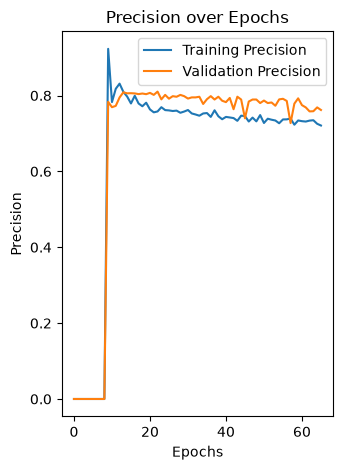

In [ ]:
plt.subplot(1, 2, 2)

plt.plot(history.history['precision'], label='Training Precision')
plt.plot(history.history['val_precision'], label='Validation Precision')

plt.title('Precision over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Precision')
plt.legend()

plt.tight_layout()
plt.show()